# Exploratory Data Analysis (EDA) — Mining Process Quality Prediction

## 1. Project Overview

This notebook performs Exploratory Data Analysis (EDA) on the cleaned Mining Process Quality Prediction dataset. The objective is to understand the distribution of process variables, identify patterns and relationships between operational parameters, and explore factors associated with iron and silica concentrate quality.

The analysis focuses on statistical summaries, target variable distributions, correlation analysis, outlier inspection, and trends over time.

## 2. Dataset Information

- **Source:** Kaggle — Quality Prediction in a Mining Process https://www.kaggle.com/code/korrapatyairit/ml-regression-quality-prediction-in-a-mining-proc/input
- **Cleaned records:** 736,282 rows
- **Columns:** 24
- **Time period:** March–September 2017
- **Data types:** Timestamp and numerical process measurements
- **Target variables:** `% Iron Concentrate` and `% Silica Concentrate`

## 3. EDA Objectives

1. Examine descriptive statistics and numerical variable distributions.
2. Analyze the distributions of iron and silica concentrate.
3. Investigate correlations between process variables and target variables.
4. Explore relationships between iron concentrate, silica concentrate, and selected operational parameters.
5. Analyze daily trends and changes in process quality over time.
6. Inspect potential outliers and unusual observations.
7. Identify useful findings to support subsequent machine learning and operational analysis.

## 4. Analysis Approach

The analysis uses Python, Pandas, NumPy, Matplotlib, and Seaborn to summarize and visualize the dataset. Correlation analysis is used to identify statistical associations, while time-series plots help reveal variations in process quality.

Potential outliers are inspected using statistical methods. These observations are not automatically removed because they may represent genuine operating conditions.

## 5. Expected Output

A set of statistical summaries, visualizations, and analytical findings describing the mining process data. These findings will support feature selection, model development, and interpretation of the machine learning results.

**Note:** Correlation and visualization results indicate patterns and associations; they do not independently establish causal relationships.

In [ ]:

from google.colab import drive
import pandas as pd
import os

# Hubungkan Google Drive
drive.mount('/content/drive')

# Lokasi dataset yang sudah dibersihkan
file_path = (
    "/content/drive/MyDrive/"
    "Mining_Process_Quality_Prediction/data/processed/"
    "mining_process_clean.csv"
)

# Baca dataset
df = pd.read_csv(file_path, parse_dates=["date"])

print("Dataset berhasil dimuat!")
print("Ukuran dataset:", df.shape)
print("Periode data:", df["date"].min(), "sampai", df["date"].max())

display(df.head())


Mounted at /content/drive
Dataset berhasil dimuat!
Ukuran dataset: (736282, 24)
Periode data: 2017-03-10 01:00:00 sampai 2017-09-09 23:00:00


,date,% Iron Feed,% Silica Feed,Starch Flow,Amina Flow,Ore Pulp Flow,Ore Pulp pH,Ore Pulp Density,Flotation Column 01 Air Flow,Flotation Column 02 Air Flow,...,Flotation Column 07 Air Flow,Flotation Column 01 Level,Flotation Column 02 Level,Flotation Column 03 Level,Flotation Column 04 Level,Flotation Column 05 Level,Flotation Column 06 Level,Flotation Column 07 Level,% Iron Concentrate,% Silica Concentrate
0,2017-03-10 01:00:00,55.2,16.98,3019.53,557.434,395.713,10.0664,1.74,249.214,253.235,...,250.884,457.396,432.962,424.954,443.558,502.255,446.370,523.344,66.91,1.31
1,2017-03-10 01:00:00,55.2,16.98,3024.41,563.965,397.383,10.0672,1.74,249.719,250.532,...,248.994,451.891,429.560,432.939,448.086,496.363,445.922,498.075,66.91,1.31
2,2017-03-10 01:00:00,55.2,16.98,3043.46,568.054,399.668,10.0680,1.74,249.741,247.874,...,248.071,451.240,468.927,434.610,449.688,484.411,447.826,458.567,66.91,1.31
3,2017-03-10 01:00:00,55.2,16.98,3047.36,568.665,397.939,10.0689,1.74,249.917,254.487,...,251.147,452.441,458.165,442.865,446.210,471.411,437.690,427.669,66.91,1.31
4,2017-03-10 01:00:00,55.2,16.98,3033.69,558.167,400.254,10.0697,1.74,250.203,252.136,...,248.928,452.441,452.900,450.523,453.670,462.598,443.682,425.679,66.91,1.31


  -Menghubungkan Colab dengan Google Drive.

-Membaca CSV hasil Data Cleaning.

-Mengubah kolom date menjadi format tanggal.

-Menampilkan jumlah baris, kolom, periode pengamatan, dan lima baris pertama.

Statistik deskriptif

In [ ]:

# EDA 1: Statistik deskriptif

# Pilih kolom numerik
numeric_df = df.select_dtypes(include="number")

# Tampilkan statistik utama
summary = numeric_df.describe().T

display(summary.round(3))


,count,mean,std,min,25%,50%,75%,max
% Iron Feed,736282.0,56.298,5.160,42.740,52.670,56.080,59.720,65.780
% Silica Feed,736282.0,14.649,6.811,1.310,8.940,13.850,19.600,33.400
Starch Flow,736282.0,2869.637,1216.018,0.002,2075.070,3020.230,3728.930,6300.230
Amina Flow,736282.0,488.166,91.254,241.669,431.836,504.352,553.336,739.538
Ore Pulp Flow,736282.0,397.571,9.705,376.249,394.248,399.238,402.967,418.641
Ore Pulp pH,736282.0,9.767,0.387,8.753,9.527,9.797,10.038,10.808
Ore Pulp Density,736282.0,1.680,0.069,1.520,1.647,1.698,1.728,1.853
Flotation Column 01 Air Flow,736282.0,280.120,29.634,175.510,250.278,299.341,300.147,373.871
Flotation Column 02 Air Flow,736282.0,277.121,30.157,175.156,250.448,296.202,300.686,375.992
Flotation Column 03 Air Flow,736282.0,281.053,28.571,176.469,250.847,298.690,300.385,364.346


Visualisasi distribusi kualitas produk

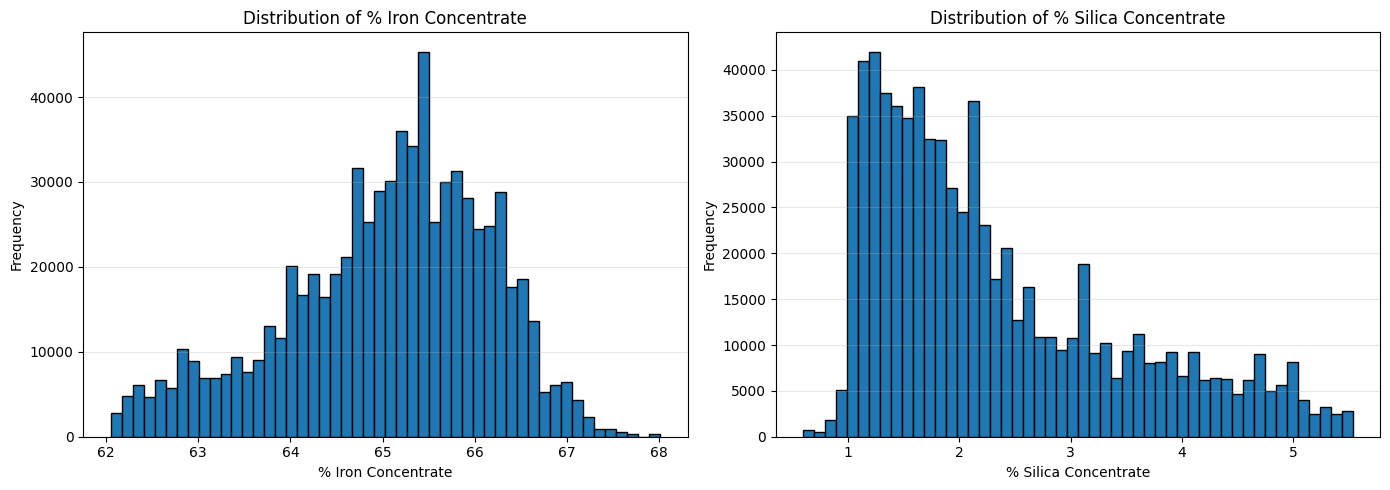

In [ ]:

import matplotlib.pyplot as plt

# Kolom target kualitas
quality_columns = [
    "% Iron Concentrate",
    "% Silica Concentrate"
]

# Buat histogram
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, quality_columns):
    ax.hist(df[col], bins=50, edgecolor="black")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


Interpretasi hasil histogram

A. % Iron Concentrate
- Sebagian besar pengamatan terkonsentrasi di sekitar 64–66%.
- Bentuk distribusinya memiliki satu area konsentrasi utama, dengan beberapa fluktuasi.
- Nilai di bawah 63% dan di atas 67% terlihat lebih jarang.

Insight awal: kadar besi relatif terkonsentrasi pada rentang tertentu. Kita perlu memeriksa statistik dan tren waktu untuk memastikannya

B. % Silica Concentrate
- Distribusinya tampak miring ke kanan (right-skewed).
- Banyak pengamatan berada di sekitar 1–2%.
- Sebagian pengamatan memiliki kadar silika lebih tinggi, hingga lebih dari 4%.

Insight awal: kadar silika memiliki variasi yang cukup lebar. Nilai tinggi perlu diperiksa untuk mengetahui kapan terjadi dan apakah berkaitan dengan perubahan proses.

Perlu diingat, histogram menunjukkan distribusi nilai, bukan penyebab perubahan kualitas. Kita belum bisa menyimpulkan bahwa parameter tertentu menyebabkan kadar besi atau silika berubah.

##Analisis korelasi

memeriksa hubungan statistik antara parameter proses dengan kedua indikator kualitas produk.

Apa yang akan kita cari?
- Korelasi positif: dua variabel cenderung meningkat bersama.
- Korelasi negatif: satu variabel cenderung meningkat ketika variabel lain menurun.
- Korelasi mendekati nol: hubungan linear yang lemah.
Catatan: korelasi tidak membuktikan sebab-akibat, dan korelasi yang lemah tidak selalu berarti tidak ada hubungan nonlinier.

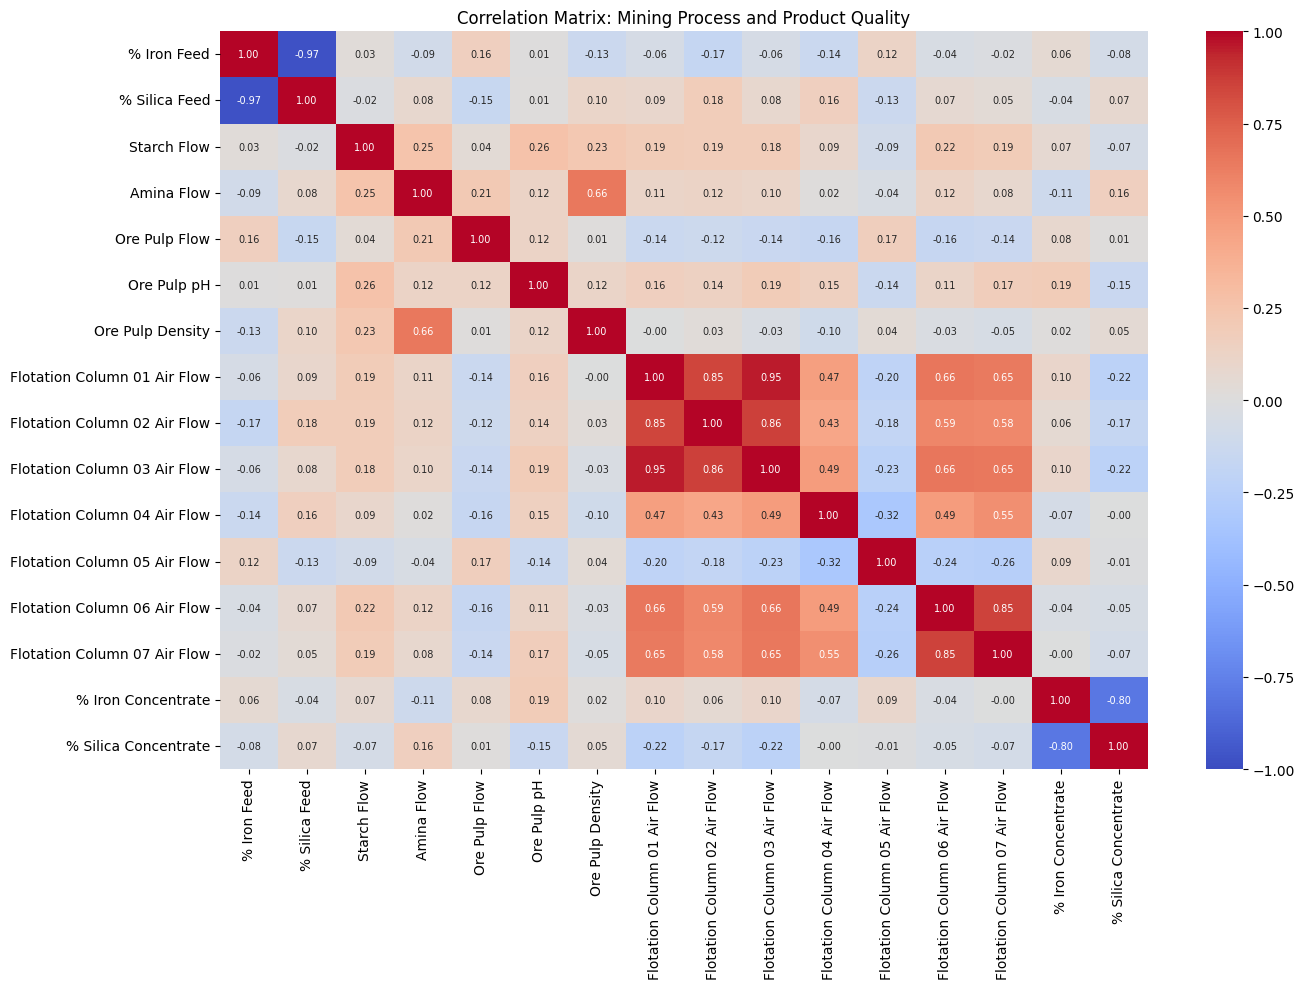

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt

# Pilih parameter proses dan indikator kualitas
corr_cols = [
    "% Iron Feed",
    "% Silica Feed",
    "Starch Flow",
    "Amina Flow",
    "Ore Pulp Flow",
    "Ore Pulp pH",
    "Ore Pulp Density",
    "Flotation Column 01 Air Flow",
    "Flotation Column 02 Air Flow",
    "Flotation Column 03 Air Flow",
    "Flotation Column 04 Air Flow",
    "Flotation Column 05 Air Flow",
    "Flotation Column 06 Air Flow",
    "Flotation Column 07 Air Flow",
    "% Iron Concentrate",
    "% Silica Concentrate"
]

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7}
)

plt.title("Correlation Matrix: Mining Process and Product Quality")
plt.tight_layout()
plt.show()


1. - % Iron Feed dan % Silica Feed
- r ≈ 0,97
- Korelasi positif sangat kuat. Kedua variabel ini bergerak bersama dalam dataset, sehingga nanti perlu diperhatikan saat membangun model.

2. Air Flow antar kolom flotasi
Beberapa pasangan menunjukkan korelasi positif tinggi, sekitar 0,85–0,95.
Ini mengindikasikan bahwa pembacaan aliran udara pada beberapa kolom memiliki pola yang serupa.

3. Kualitas produk
- Pada heatmap, korelasi linear antara sebagian besar parameter yang dipilih dengan Iron Concentrate dan Silica Concentrate terlihat relatif lemah.
Kita perlu menyelidiki hubungan waktu, pola nonlinier, dan kemungkinan pengaruh gabungan beberapa parameter.


##Analisis korelasi khusus kualitas

Sekarang kita urutkan semua parameter berdasarkan korelasinya terhadap kedua target. Ini akan membantu kita menentukan variabel yang perlu diteliti lebih lanjut

In [ ]:

# EDA: Korelasi parameter terhadap kualitas produk

target_cols = [
    "% Iron Concentrate",
    "% Silica Concentrate"
]

feature_cols = [
    col for col in df.select_dtypes(include="number").columns
    if col not in target_cols
]

for target in target_cols:
    print(f"\nKorelasi dengan {target}")

    correlation = (
        df[feature_cols + [target]]
        .corr(numeric_only=True)[target]
        .drop(target)
        .sort_values(key=abs, ascending=False)
    )

    display(correlation.to_frame("correlation").round(3))



Korelasi dengan % Iron Concentrate


,correlation
Ore Pulp pH,0.192
Flotation Column 05 Level,0.160
Flotation Column 07 Level,0.146
Flotation Column 04 Level,0.136
Amina Flow,-0.111
Flotation Column 03 Air Flow,0.100
Flotation Column 01 Air Flow,0.098
Flotation Column 05 Air Flow,0.088
Ore Pulp Flow,0.083
Flotation Column 06 Level,0.082



Korelasi dengan % Silica Concentrate


,correlation
Flotation Column 01 Air Flow,-0.219
Flotation Column 03 Air Flow,-0.219
Flotation Column 05 Level,-0.168
Flotation Column 02 Air Flow,-0.167
Amina Flow,0.157
Flotation Column 04 Level,-0.149
Ore Pulp pH,-0.147
Flotation Column 07 Level,-0.141
Flotation Column 06 Level,-0.102
% Iron Feed,-0.077


Interpretasi hasil:

1. korelasi Iron Concentrate
Dari screenshot kamu, variabel dengan korelasi absolut terbesar terhadap % Iron Concentrate adalah:
Parameter proses	Korelasi	Interpretasi awal
Ore Pulp pH	+0,192	Hubungan positif lemah
Flotation Column 05 Level	+0,160	Hubungan positif lemah
Flotation Column 07 Level	+0,146	Hubungan positif lemah
Flotation Column 04 Level	+0,136	Hubungan positif lemah
Amina Flow	−0,111	Hubungan negatif lemah
Apa artinya?
    - Ore Pulp pH memiliki korelasi linear paling kuat di antara variabel yang terlihat, tetapi hubungannya masih tergolong lemah.
    - Level pada beberapa kolom flotasi juga menunjukkan hubungan positif yang lemah.
    - Amina Flow memiliki hubungan negatif yang lemah dengan kadar besi konsentrat.
    
Korelasi bukan bukti sebab-akibat. Parameter dengan korelasi kecil tetap mungkin berguna dalam model prediksi apabila memiliki hubungan nonlinier atau berinteraksi dengan parameter lainnya

2. korelasi Silica Concentrate
  - Air Flow pada kolom 01 dan 03 menunjukkan korelasi negatif paling kuat di antara parameter yang terlihat. Artinya, nilai Air Flow yang lebih tinggi cenderung berkaitan dengan kadar silika yang lebih rendah dalam data ini.
  - Amina Flow memiliki korelasi positif lemah, yaitu sekitar +0,157.
  - Seluruh korelasi yang terlihat masih tergolong lemah. Jadi, kita belum bisa menyimpulkan bahwa perubahan satu parameter secara langsung menyebabkan perubahan kualitas.

##Analisis tren kualitas berdasarkan waktu

Sekarang kita periksa bagaimana kualitas produk berubah dari Maret hingga September 2017. Ini penting untuk mengetahui apakah ada tren, fluktuasi, atau periode yang berbeda

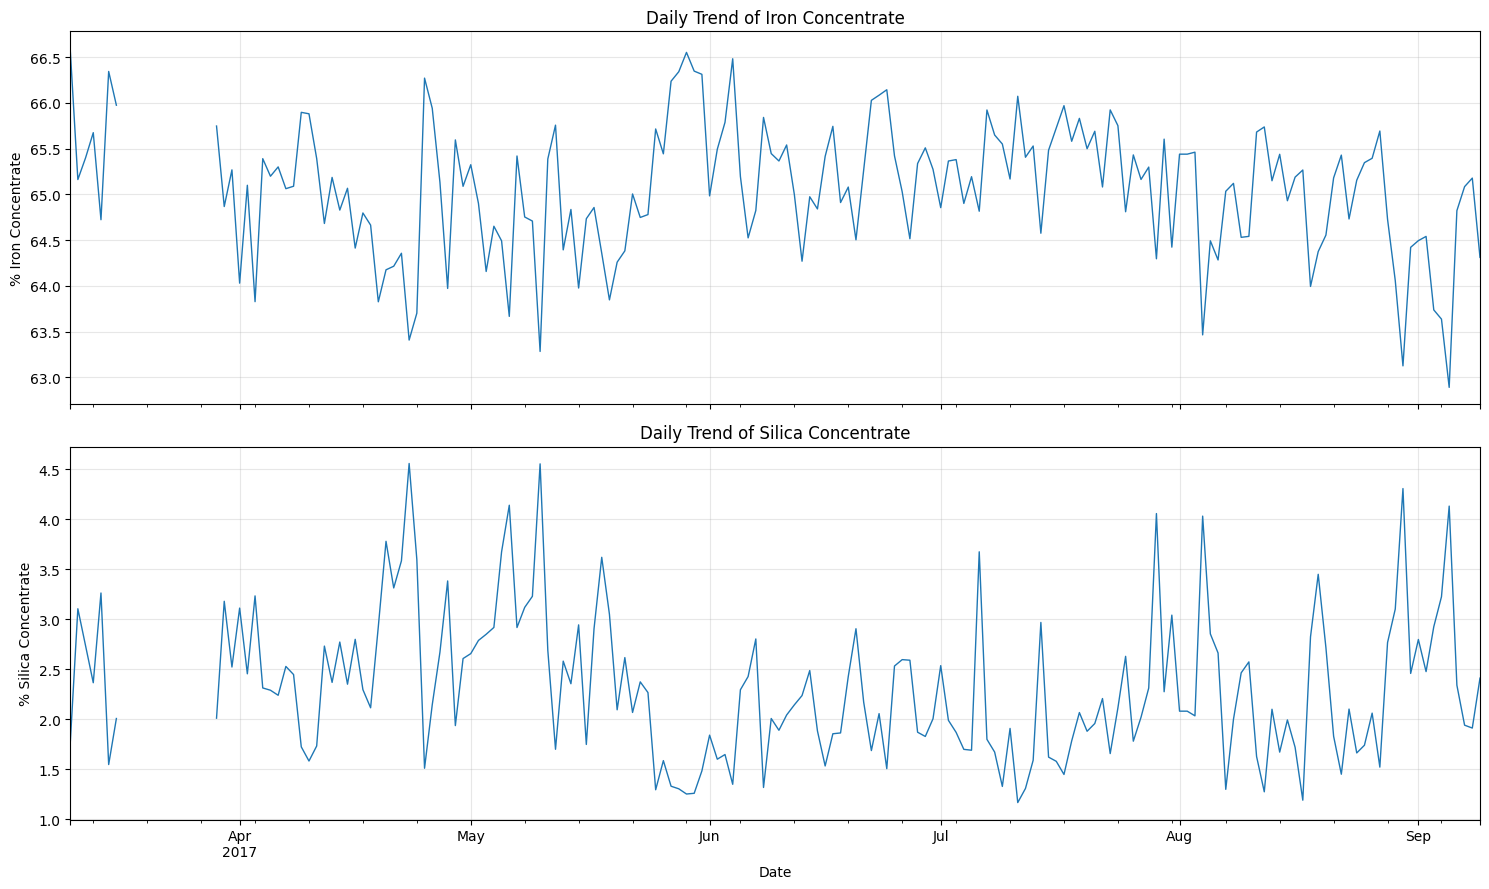

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

# Ringkas kualitas produk per hari
daily_quality = (
    df.set_index("date")[
        ["% Iron Concentrate", "% Silica Concentrate"]
    ]
    .resample("D")
    .mean()
)

# Plot tren harian
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

daily_quality["% Iron Concentrate"].plot(
    ax=axes[0], linewidth=1
)
axes[0].set_title("Daily Trend of Iron Concentrate")
axes[0].set_ylabel("% Iron Concentrate")
axes[0].grid(alpha=0.3)

daily_quality["% Silica Concentrate"].plot(
    ax=axes[1], linewidth=1
)
axes[1].set_title("Daily Trend of Silica Concentrate")
axes[1].set_ylabel("% Silica Concentrate")
axes[1].set_xlabel("Date")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


1. Interpretasi grafik tren kualitas
- A. Iron Concentrate
Dari grafik Maret–September 2017, kadar besi terlihat berfluktuasi, umumnya di sekitar 64–66%. Ada beberapa penurunan tajam, terutama mendekati akhir periode pengamatan.
Insight awal: proses menghasilkan kadar besi yang berubah-ubah, sehingga periode penurunan kualitas perlu diteliti lebih lanjut.



- B. Silica Concentrate
Kadar silika terlihat lebih berfluktuasi. Sebagian besar nilai berada di kisaran sekitar 1,5–2,5%, tetapi ada beberapa lonjakan hingga di atas 4%.
Insight awal: lonjakan silika dapat menjadi kandidat periode untuk investigasi parameter proses yang berubah pada waktu yang sama.


Perlu diingat, grafik ini menampilkan rata-rata harian. Kita belum bisa menyimpulkan penyebab fluktuasi atau bahwa proses mengalami kegagalan tanpa pemeriksaan tambahan.

##Analisis hubungan antarparameter dan kualitas

Sekarang kita akan membuat scatter plot untuk melihat hubungan langsung antara dua parameter yang korelasinya paling menonjol dalam analisis sebelumnya:
- Ore Pulp pH terhadap % Iron Concentrate
- Flotation Column 01 Air Flow terhadap % Silica Concentrate
Karena dataset berisi lebih dari 736 ribu baris, kita ambil sampel acak 5.000 baris agar grafik tetap ringan dan mudah dibaca.

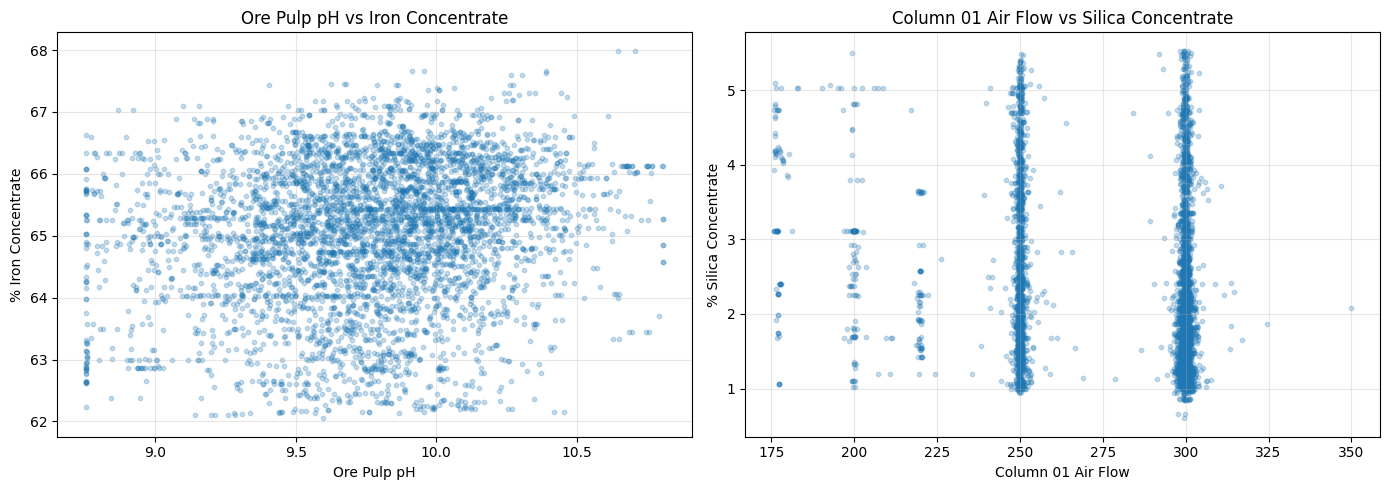

In [ ]:

import matplotlib.pyplot as plt

# Ambil sampel agar grafik lebih ringan
sample_df = df.sample(
    n=min(5000, len(df)),
    random_state=42
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# pH vs Iron Concentrate
axes[0].scatter(
    sample_df["Ore Pulp pH"],
    sample_df["% Iron Concentrate"],
    alpha=0.25,
    s=10
)
axes[0].set_title("Ore Pulp pH vs Iron Concentrate")
axes[0].set_xlabel("Ore Pulp pH")
axes[0].set_ylabel("% Iron Concentrate")
axes[0].grid(alpha=0.3)

# Air Flow vs Silica Concentrate
axes[1].scatter(
    sample_df["Flotation Column 01 Air Flow"],
    sample_df["% Silica Concentrate"],
    alpha=0.25,
    s=10
)
axes[1].set_title("Column 01 Air Flow vs Silica Concentrate")
axes[1].set_xlabel("Column 01 Air Flow")
axes[1].set_ylabel("% Silica Concentrate")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


Grafik 1 — Ore Pulp pH vs Iron Concentrate
- Mayoritas kadar besi terkumpul di kisaran 64–66%.
- Nilai pH banyak berada di sekitar 9,5–10,0.
- Tidak terlihat hubungan linear yang sangat kuat secara visual.
Insight: pH saja kemungkinan belum cukup untuk menjelaskan perubahan kadar besi. Kita perlu mempertimbangkan parameter proses lainnya.

Grafik 2 — Column 01 Air Flow vs Silica Concentrate
- Data membentuk kelompok vertikal di sekitar nilai air flow 250 dan 300.
- Kadar silika tersebar cukup lebar pada kedua kelompok.
- Hubungan yang jelas belum dapat dipastikan hanya dari grafik ini.
Insight: air flow perlu dianalisis bersama variabel lain untuk memahami perubahan kadar silika.

##Analisis kualitas berdasarkan kategori

Sekarang kita buat perbandingan antara kondisi kualitas produk rendah, sedang, dan tinggi. Kita gunakan kuantil agar setiap kelompok dibentuk berdasarkan distribusi aktual dataset.

Apakah kelompok dengan kadar besi tinggi memiliki kadar silika yang lebih rendah?

Berapa banyak observasi pada masing-masing kelompok?

Apakah ada pola yang bisa menjadi dasar rekomendasi perbaikan proses?

Ukuran dataset: (736282, 24)
Kolom target tersedia: True True


,Average_Iron,Average_Silica,Number_of_Records
Iron Quality Group,,,
Low,63.769,3.433,247279
Medium,65.191,2.050,243980
High,66.200,1.487,245023


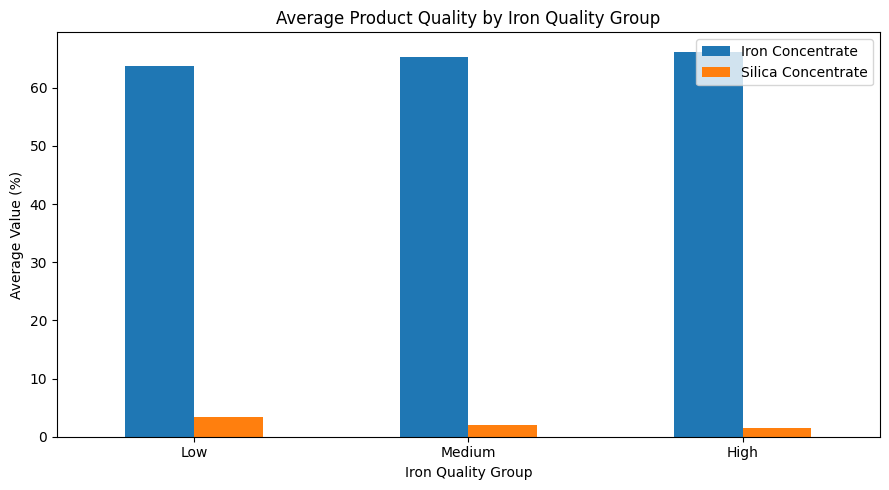

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Gunakan dataset yang sudah dibersihkan
eda_df = df.copy()

# Pastikan kolom target tersedia
print("Ukuran dataset:", eda_df.shape)
print("Kolom target tersedia:",
      "% Iron Concentrate" in eda_df.columns,
      "% Silica Concentrate" in eda_df.columns)

# Pastikan kolom target berbentuk angka
eda_df["% Iron Concentrate"] = pd.to_numeric(
    eda_df["% Iron Concentrate"], errors="coerce"
)
eda_df["% Silica Concentrate"] = pd.to_numeric(
    eda_df["% Silica Concentrate"], errors="coerce"
)

# Hapus baris yang kosong pada kedua kolom target
eda_df = eda_df.dropna(
    subset=["% Iron Concentrate", "% Silica Concentrate"]
).copy()

# Bagi kadar besi menjadi tiga kelompok
eda_df["Iron Quality Group"] = pd.qcut(
    eda_df["% Iron Concentrate"],
    q=3,
    labels=["Low", "Medium", "High"],
    duplicates="drop"
)

# Buat tabel ringkasan
quality_summary = eda_df.groupby(
    "Iron Quality Group",
    observed=True
).agg(
    Average_Iron=("% Iron Concentrate", "mean"),
    Average_Silica=("% Silica Concentrate", "mean"),
    Number_of_Records=("% Iron Concentrate", "size")
).round(3)

display(quality_summary)

# Buat grafik
quality_summary[
    ["Average_Iron", "Average_Silica"]
].plot(kind="bar", figsize=(9, 5))

plt.title("Average Product Quality by Iron Quality Group")
plt.xlabel("Iron Quality Group")
plt.ylabel("Average Value (%)")
plt.xticks(rotation=0)
plt.legend(["Iron Concentrate", "Silica Concentrate"])
plt.tight_layout()
plt.show()

##Identifikasi anomali dan pola operasional

Kita akan melihat apakah ada nilai ekstrem (outliers) pada parameter proses pertambangan. Ini penting sebelum membuat analisis SQL dan dashboard Power BI.

,Column,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,% Iron Feed,42.095,70.295,0,0.00
1,% Silica Feed,-7.050,35.590,0,0.00
2,Ore Pulp pH,8.761,10.804,10986,1.49
3,Ore Pulp Density,1.526,1.850,43195,5.87
4,% Iron Concentrate,62.135,68.095,1590,0.22
5,% Silica Concentrate,-0.915,5.365,4757,0.65


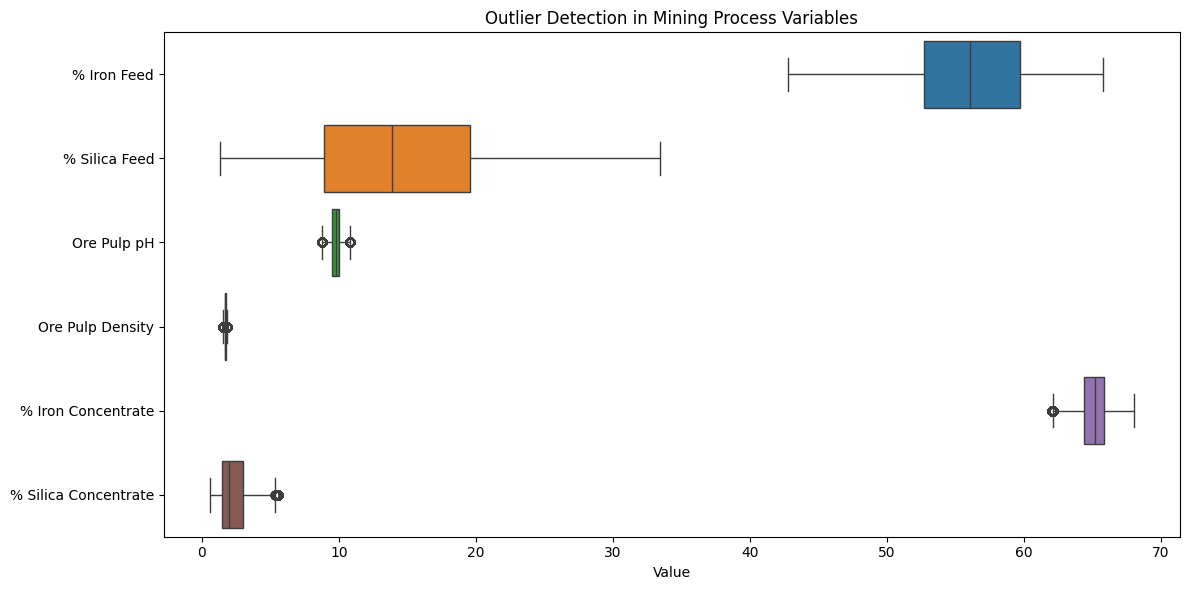

In [ ]:

# EDA 6: Deteksi Outliers dengan metode IQR

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pilih parameter proses dan kualitas produk
selected_columns = [
    "% Iron Feed",
    "% Silica Feed",
    "Ore Pulp pH",
    "Ore Pulp Density",
    "% Iron Concentrate",
    "% Silica Concentrate"
]

# Pastikan kolom tersedia
selected_columns = [
    col for col in selected_columns if col in eda_df.columns
]

# Hitung jumlah outliers dengan metode IQR
outlier_results = []

for col in selected_columns:
    Q1 = eda_df[col].quantile(0.25)
    Q3 = eda_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (eda_df[col] < lower) |
        (eda_df[col] > upper)
    ).sum()

    outlier_results.append({
        "Column": col,
        "Lower Bound": round(lower, 3),
        "Upper Bound": round(upper, 3),
        "Outlier Count": int(count),
        "Outlier Percentage": round(
            count / len(eda_df) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_results)
display(outlier_df)

# Visualisasi boxplot
plt.figure(figsize=(12, 6))
sns.boxplot(data=eda_df[selected_columns], orient="h")
plt.title("Outlier Detection in Mining Process Variables")
plt.xlabel("Value")
plt.tight_layout()
plt.show()


Interpretasi hasil grafik
- % Iron Feed: sebaran data relatif terkonsentrasi pada kisaran nilai tertentu.
- % Silica Feed: memiliki sebaran lebih lebar dibandingkan beberapa parameter lainnya.
- Ore Pulp pH dan Ore Pulp Density: sebarannya relatif sempit.
- % Iron Concentrate: mayoritas data berada di sekitar 65–66%.
- % Silica Concentrate: sebarannya lebih lebar dan terlihat beberapa titik di luar whisker.
Catatan: boxplot ini menggunakan skala sumbu X yang sama untuk variabel dengan satuan dan rentang berbeda. Karena itu, lebar boxplot tidak bisa langsung dibandingkan untuk menentukan variabel yang paling bervariasi.

##kesimpulan EDA otomatis untuk mencatat temuan utama yang bisa dimasukkan ke README

In [ ]:

# EDA 7: Ringkasan Temuan Utama

print("=" * 55)
print("EDA SUMMARY - MINING PROCESS QUALITY")
print("=" * 55)

print(f"\nTotal observasi: {len(eda_df):,}")
print(f"Total kolom: {eda_df.shape[1]}")

print("\n--- RATA-RATA KUALITAS PRODUK ---")
print(
    "Rata-rata Iron Concentrate:",
    round(eda_df["% Iron Concentrate"].mean(), 3), "%"
)
print(
    "Rata-rata Silica Concentrate:",
    round(eda_df["% Silica Concentrate"].mean(), 3), "%"
)

print("\n--- KORELASI DENGAN KUALITAS PRODUK ---")

corr = eda_df.select_dtypes(
    include="number"
).corr()

for target in ["% Iron Concentrate", "% Silica Concentrate"]:
    if target in corr.columns:
        print(f"\nTop 5 korelasi untuk {target}:")
        print(
            corr[target]
            .drop(target)
            .sort_values(
                key=lambda s: s.abs(),
                ascending=False
            )
            .head(5)
            .round(3)
        )

print("\n--- STATUS DATA ---")
print("Missing values:", eda_df.isna().sum().sum())
print("Duplikat baris:", eda_df.duplicated().sum())
print("\nEDA selesai.")


EDA SUMMARY - MINING PROCESS QUALITY

Total observasi: 736,282
Total kolom: 25

--- RATA-RATA KUALITAS PRODUK ---
Rata-rata Iron Concentrate: 65.049 %
Rata-rata Silica Concentrate: 2.327 %

--- KORELASI DENGAN KUALITAS PRODUK ---

Top 5 korelasi untuk % Iron Concentrate:
% Silica Concentrate        -0.801
Ore Pulp pH                  0.192
Flotation Column 05 Level    0.160
Flotation Column 07 Level    0.146
Flotation Column 04 Level    0.136
Name: % Iron Concentrate, dtype: float64

Top 5 korelasi untuk % Silica Concentrate:
% Iron Concentrate             -0.801
Flotation Column 01 Air Flow   -0.219
Flotation Column 03 Air Flow   -0.219
Flotation Column 05 Level      -0.168
Flotation Column 02 Air Flow   -0.167
Name: % Silica Concentrate, dtype: float64

--- STATUS DATA ---
Missing values: 0
Duplikat baris: 0

EDA selesai.
